# Inflación en Argentina, 2017-2026

Análisis de la inflación mensual e interanual en Argentina usando el IPC nivel general nacional (base dic 2016) del INDEC.

**Fuente de datos:** API de series de tiempo del Gobierno argentino (datos.gob.ar), serie `148.3_INIVELNAL_DICI_M_26`.

**Pregunta:** ¿cómo evolucionó la inflación en Argentina en los últimos 9 años y qué tan fuerte fue el pico de 2023-2024?

In [21]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

## Inflación mensual

La serie del IPC es un índice con base 100 en diciembre de 2016. Para obtener la inflación de cada mes se calcula la variación porcentual respecto del mes anterior.

El pico se dio en diciembre de 2023, con una inflación de alrededor de 25,5% en un solo mes.

In [22]:
from io import StringIO
import pandas as pd
import requests

# 1. Descarga desde la API oficial de datos abiertos
url = "https://apis.datos.gob.ar/series/api/series/"
parametros = {
    "ids": "148.3_INIVELNAL_DICI_M_26",
    "representation_mode": "percent_change",  # Devuelve la variación mensual
    "format": "csv",
    "start_date": "2017-01-01",
    "limit": 1000,
}

r = requests.get(url, params=parametros)
ipc = pd.read_csv(StringIO(r.text))
ipc.columns = ["fecha", "inflacion_mensual"]

# 2. Formato de fecha y conversión a porcentaje (%)
ipc["fecha"] = pd.to_datetime(ipc["fecha"])
ipc = ipc.sort_values("fecha").dropna().reset_index(drop=True)
ipc["inflacion_mensual"] = ipc["inflacion_mensual"] * 100

# 3. Mostrar primeros 5 y últimos 5 meses
print("--- PRIMEROS 5 MESES DE LA SERIE ---")
print(ipc.head(5).to_string(index=False))

print("\n--- ÚLTIMOS 5 MESES DE LA SERIE ---")
print(ipc.tail(5).to_string(index=False))

# 4. Guardar los datos procesados para usarlos en el gráfico
ipc.to_csv("inflacion_mensual.csv", index=False)


--- PRIMEROS 5 MESES DE LA SERIE ---
     fecha  inflacion_mensual
2017-02-01           2.067216
2017-03-01           2.374190
2017-04-01           2.655830
2017-05-01           1.434750
2017-06-01           1.192073

--- ÚLTIMOS 5 MESES DE LA SERIE ---
     fecha  inflacion_mensual
2026-04-01           2.582180
2026-05-01           2.149972
2026-06-01           1.886871
2026-07-01           2.113772
2026-08-01           1.659206



Pico máximo de inflación: Diciembre 2023 con 25.5% de inflación mensual



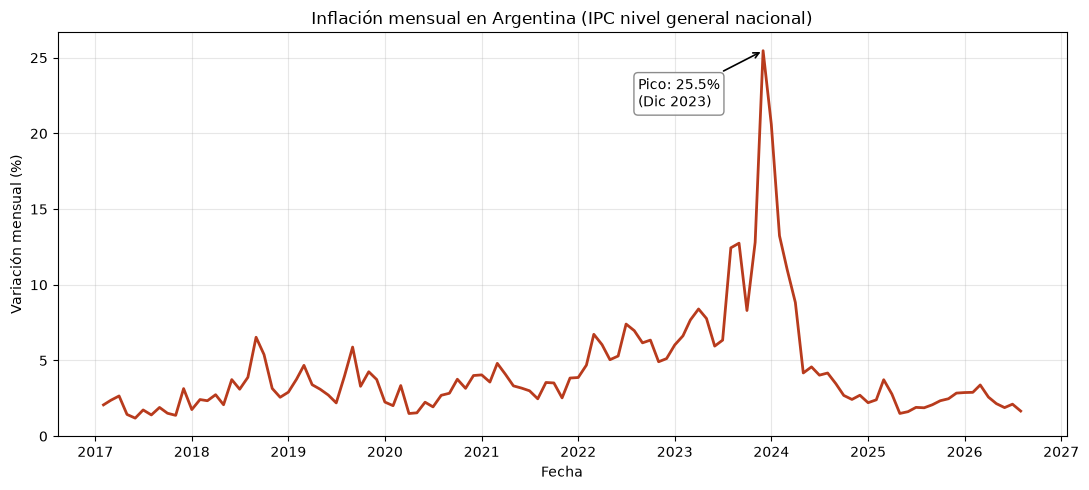

In [26]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Leer los datos guardados
ipc = pd.read_csv("inflacion_mensual.csv")
ipc["fecha"] = pd.to_datetime(ipc["fecha"])

# 2. Detectar el pico máximo
max_idx = ipc["inflacion_mensual"].idxmax()
max_row = ipc.loc[max_idx]
max_fecha = max_row["fecha"]
max_val = max_row["inflacion_mensual"]

# Mapeo de meses a español
meses_es = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre",
}
mes_nombre = meses_es[max_fecha.month]

# 3. Imprimir el texto informativo antes del gráfico
print("\n" + "=" * 65)
print(
    f"Pico máximo de inflación: {mes_nombre} {max_fecha.year} con {max_val:.1f}% de inflación mensual"
)
print("=" * 65 + "\n")

# 4. Armar el gráfico
plt.figure(figsize=(11, 5))
plt.plot(ipc["fecha"], ipc["inflacion_mensual"], color="#b83b1d", linewidth=2)

# Anotación en el pico máximo
plt.annotate(
    f"Pico: {max_val:.1f}%\n({mes_nombre[:3]} {max_fecha.year})",
    xy=(max_fecha, max_val),
    xytext=(-90, -40),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)

plt.title("Inflación mensual en Argentina (IPC nivel general nacional)")
plt.xlabel("Fecha")
plt.ylabel("Variación mensual (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar gráfico
plt.show()

## Inflación interanual

La variación interanual compara cada mes con el mismo mes del año anterior. Suaviza los saltos mensuales y es la medida más usada en informes económicos.

El máximo se alcanzó en la primera mitad de 2024, con valores cercanos al 290%. Desde entonces la inflación interanual bajó fuerte y se estabilizó en torno al 30-35% en 2025 y 2026.


Pico máximo de inflación interanual: Abril 2024 con 289.4% interanual



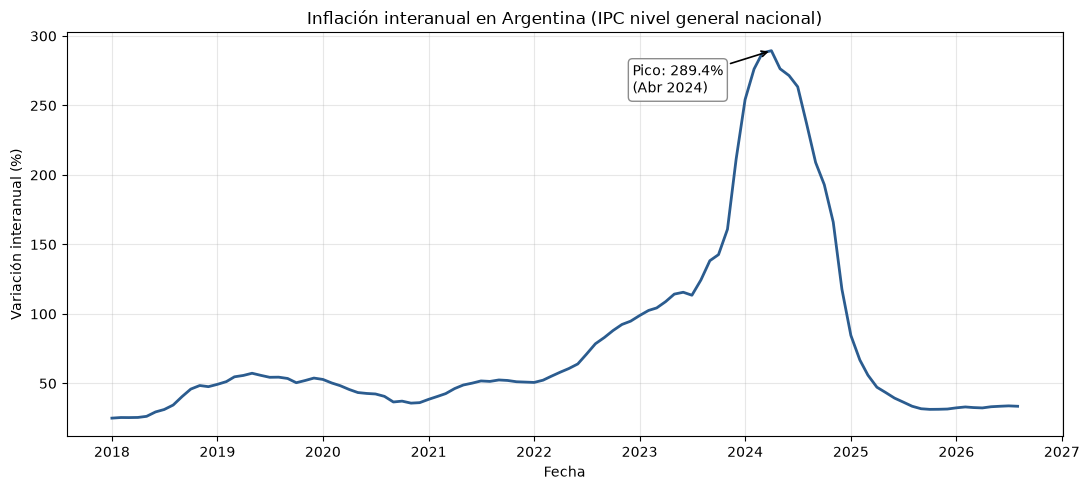

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Leer los datos mensuales que YA descargaste
ipc = pd.read_csv("inflacion_mensual.csv")
ipc["fecha"] = pd.to_datetime(ipc["fecha"])

# 2. Calcular la inflación interanual (acumulado de 12 meses móviles)
ipc["inflacion_interanual"] = (
    (1 + ipc["inflacion_mensual"] / 100).rolling(12).apply(np.prod, raw=True) - 1
) * 100

# Eliminamos los primeros 11 meses que quedan vacíos (NaN) al no tener 12 meses hacia atrás
ipc_interanual = ipc.dropna(subset=["inflacion_interanual"]).reset_index(
    drop=True
)

# 3. Detectar el pico máximo interanual
max_idx = ipc_interanual["inflacion_interanual"].idxmax()
max_row = ipc_interanual.loc[max_idx]
max_fecha = max_row["fecha"]
max_val = max_row["inflacion_interanual"]

# Mapeo de meses a español
meses_es = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre",
}
mes_nombre = meses_es[max_fecha.month]

# 4. Texto informativo antes del gráfico
print("\n" + "=" * 68)
print(
    f"Pico máximo de inflación interanual: {mes_nombre} {max_fecha.year} con {max_val:.1f}% interanual"
)
print("=" * 68 + "\n")

# 5. Gráfico interanual
plt.figure(figsize=(11, 5))
plt.plot(
    ipc_interanual["fecha"],
    ipc_interanual["inflacion_interanual"],
    color="#2b5c8f",
    linewidth=2,
)

# Anotación en el pico máximo
plt.annotate(
    f"Pico: {max_val:.1f}%\n({mes_nombre[:3]} {max_fecha.year})",
    xy=(max_fecha, max_val),
    xytext=(-100, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9),
)

plt.title("Inflación interanual en Argentina (IPC nivel general nacional)")
plt.xlabel("Fecha")
plt.ylabel("Variación interanual (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar gráfico
plt.show()